# XTTS-v2 experiments

This notebook evaluates Coqui XTTS-v2 on a single English voice from LJSpeech. It contains a zero-shot reference and two fine-tuning runs, labelled **Exp 0**, **Exp A** and **Exp B**.

**Group members:**

- **Adi Issa:** a1987954
- **Gaoyuan Chen:** a1993974
- **Zaid Ul Quadir Qazi:** a1990366

**Date:** 1 November 2026

**Pretrained model:** [Coqui XTTS-v2](https://huggingface.co/coqui/XTTS-v2)

The saved outputs include training logs, evaluation results, figures and playable audio. The final section compares the three runs and explains why XTTS was kept outside the main report.


### Connect storage and install dependencies

Mount Google Drive, locate the LJSpeech archive and create the folders for results, checkpoints and generated WAV files. The installation command provides the packages used below.


In [1]:
%pip install -q "coqui-tts[codec]" openai-whisper jiwer unidecode nemo_text_processing

import os
import subprocess
from pathlib import Path

from google.colab import drive
drive.mount("/content/drive")


PROJECT_ROOT = Path("/content/drive/MyDrive/Zaid")       # folder that holds LJSpeech-1.1.tar.bz2
ARCHIVE_PATH = PROJECT_ROOT / "LJSpeech-1.1.tar.bz2"

if not ARCHIVE_PATH.is_file() and Path("/content/LJSpeech-1.1.tar.bz2").is_file():
    PROJECT_ROOT = Path("/content")                                                  # archive uploaded directly to the Colab session
    ARCHIVE_PATH = PROJECT_ROOT / "LJSpeech-1.1.tar.bz2"
assert ARCHIVE_PATH.is_file(), f"LJSpeech archive not found: {ARCHIVE_PATH}"

DATA_ROOT = Path("/content/LJSpeech-1.1")                                            # extracted to the Colab local disk (fast reads)
WAV_DIR = DATA_ROOT / "wavs"
if not (DATA_ROOT / "metadata.csv").is_file():
    print("Extracting", ARCHIVE_PATH, "(a few minutes) ...")
    subprocess.run(["tar", "-xjf", str(ARCHIVE_PATH), "-C", "/content"], check=True)

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR = PROJECT_ROOT / "wav_examples"                         # Folder to save waves
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BASE_MODEL_DIR = Path("/content/xtts_v2_base")                     # Pretrained XTTS-v2 files, downloaded when the model is loaded.
BASE_MODEL_DIR.mkdir(parents=True, exist_ok=True)

os.environ["COQUI_TOS_AGREED"] = "1"                               # Coqui Public Model License (non-commercial use)
os.environ["TOKENIZERS_PARALLELISM"] = "false"

print("Metadata:", (DATA_ROOT / "metadata.csv").exists())
print("WAV files:", len(list(WAV_DIR.glob("*.wav"))))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
Extracting /content/drive/MyDrive/Zaid/LJSpeech-1.1.tar.bz2 (a few minutes) ...
Metadata: True
WAV files: 13100


### Import libraries

Load the tools for data preparation, XTTS training, speech generation and Whisper-based evaluation. The cell also prints the Python, PyTorch, CUDA and GPU details for the runtime.


In [2]:
import csv
import gc
import random
import sys
import time

import jiwer
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn.functional as F
import torchaudio
import whisper

from IPython.display import Audio, display
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from unidecode import unidecode
from nemo_text_processing.text_normalization.normalize import Normalizer
from huggingface_hub import snapshot_download

# XTTS-v2 building blocks from the Coqui TTS toolkit (coqui-tts, https://github.com/idiap/coqui-ai-TTS)
import TTS.tts.models.xtts as xtts_module
from TTS.tts.configs.xtts_config import XttsConfig
from TTS.tts.models.xtts import Xtts
from TTS.tts.layers.tortoise.arch_utils import TorchMelSpectrogram
from TTS.tts.layers.xtts.dvae import DiscreteVAE

print("Python:", sys.version.split()[0], "| torch:", torch.__version__, "| CUDA:", torch.version.cuda,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Python: 3.13.16 | torch: 2.11.0+cu130 | CUDA: 13.0 | GPU: NVIDIA A100-SXM4-40GB


### Set the configuration and random seeds

Use seed 42 throughout. Fine-tuning uses an effective batch size of eight, formed from microbatches of four with two accumulation steps, and a budget of 20 epochs. Exp A uses a learning rate of `1e-6` and Exp B uses `1e-7`.


In [ ]:
SEED = 42
RUN_PREFIX = "XTTS_"            # prefix of every saved output, e.g. wav_examples/XTTS_expA_01.wav
MAX_SAMPLES_A = 1000
MAX_SAMPLES_B = 2000
BATCH_SIZE = 8                  # samples per weight update
MICRO_BATCH = 4                 # Examples per forward pass. Use eight if GPU memory permits.
GRAD_ACCUM = BATCH_SIZE // MICRO_BATCH
LEARNING_RATE_A = 1e-6
LEARNING_RATE_B = 1e-7
EPOCHS = 20
NUM_WORKERS = 8                 # DataLoader workers
SAMPLE_RATE = 22050             # XTTS-v2 training rate (native LJSpeech rate)
OUTPUT_SAMPLE_RATE = 24000      # XTTS-v2 HiFi-GAN output rate
ASR_SAMPLE_RATE = 16000         # Whisper input rate

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

def sync():
    # wait for the GPU so that time.time() measures finished work
    if DEVICE == "cuda":
        torch.cuda.synchronize()

def free_memory():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

print("Device:", DEVICE)
print(f"Batch {BATCH_SIZE} = micro-batch {MICRO_BATCH} x gradient accumulation {GRAD_ACCUM}")

Device: cuda
Batch 8 = micro-batch 4 x gradient accumulation 2


## Dataset preparation

### Source data

LJSpeech 1.1 contains 13,100 recordings from one female reader at 22,050 Hz. The archive supplies `metadata.csv` and a `wavs/` directory. The setup cell extracts it to `/content/LJSpeech-1.1`.

### Audio preparation

- **Sample rate:** Training audio stays at 22,050 Hz for the XTTS conditioning mel features and DVAE targets. XTTS generates 24,000 Hz audio, which is resampled to 16,000 Hz for Whisper.
- **Silence and padding:** Original pauses are retained. Batches are padded with zeros, and true sequence lengths allow the model to exclude padded target positions from its loss.
- **Normalisation:** Mel features use the pretrained `mel_stats.pth` values. File paths are checked before sampling, and rows without an existing WAV file are excluded.

### Text preparation

The `normalised_text` field supplies the transcript. `clean_text()` converts accented characters to ASCII, expands the listed abbreviations, lowercases the text, removes quotes and brackets, replaces hyphens, colons and semicolons with spaces, and collapses repeated whitespace. New prompts and WER comparisons also use NeMo number expansion.

These limited rules provide consistent spoken forms while keeping the input compatible with the pretrained XTTS-v2 BPE tokenizer. The tokenizer uses `vocab.json` and the English language tag. No separate phonemizer is used.

### Fixed data selections

The retained experiments use the same **1,000-recording selection**, divided into **800 training, 100 validation and 100 test recordings**, with seed 42.

The selection is drawn from a seeded 2,000-recording pool, first divided into 1,600 training, 200 validation and 200 test recordings. Sampling within those roles creates the 800/100/100 selection. This intermediate pool preserves the sampling sequence and the fixed speaker reference used in the saved runs. Its split and loader statistics remain visible below. It is not an additional trained experiment in this submission.


### Load the LJSpeech metadata

Read the utterance identifiers and paired transcripts before constructing audio paths.


In [3]:
data = pd.read_csv( DATA_ROOT / "metadata.csv", sep="|" , names=["utt_id", "raw_text", "normalised_text"], quoting=csv.QUOTE_NONE)          #  encoding="utf-8" , header=None

print(data.head(10).to_string(index=False))

assert len(data) == 13100
assert data["normalised_text"].notna().all()

    utt_id                                                                                                                                                    raw_text                                                                                                                                             normalised_text
LJ001-0001     Printing, in the only sense with which we are at present concerned, differs from most if not from all the arts and crafts represented in the Exhibition     Printing, in the only sense with which we are at present concerned, differs from most if not from all the arts and crafts represented in the Exhibition
LJ001-0002                                                                                                                              in being comparatively modern.                                                                                                                              in being comparatively modern.
LJ001-0003 For although the Chi

### Inspect character frequencies before cleaning

The histogram provides a check of the transcript characters before normalisation.


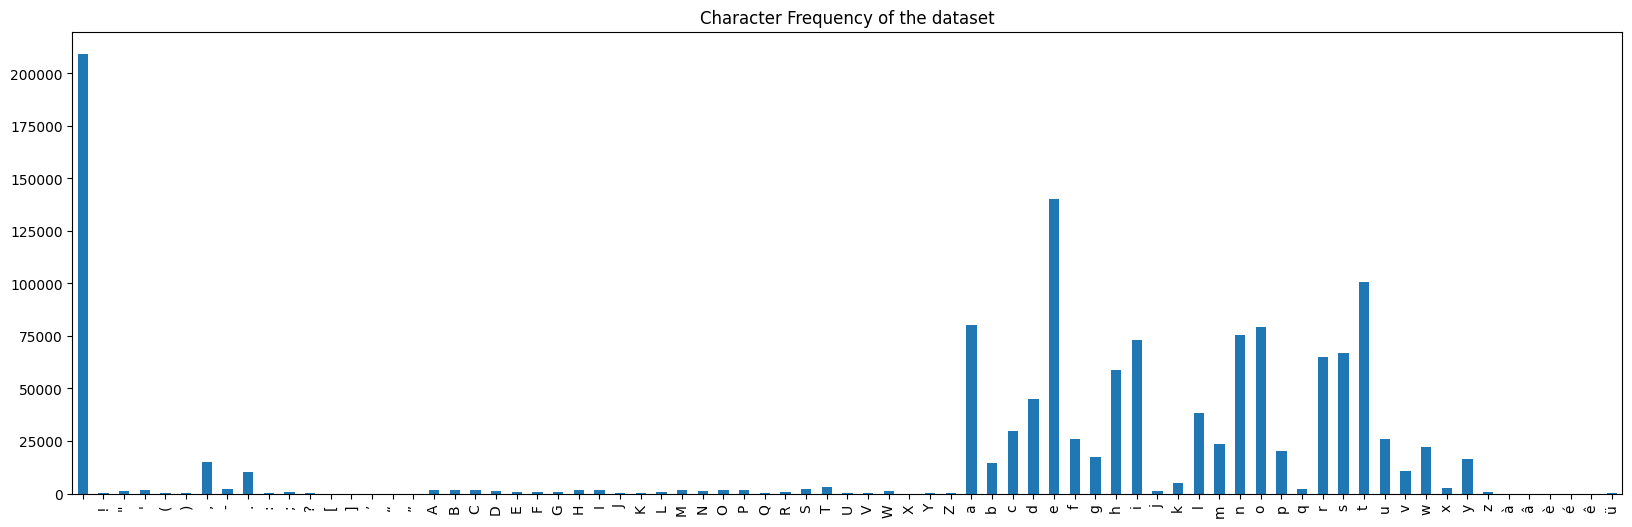

In [4]:
counts = pd.Series(list("".join(data["normalised_text"].dropna()))).value_counts()

symbols = sorted(c for c in counts.index if not c.isalnum())
letters = sorted((c for c in counts.index if c.isalpha()))
other = sorted(c for c in counts.index if c not in symbols + letters)

counts = counts.reindex(symbols + letters + other)
counts.plot.bar(figsize=(20, 6), title="Character Frequency of the dataset")
plt.show()

### Clean transcripts and check audio paths

Apply the text rules, construct each WAV path and retain recordings whose files exist.


In [5]:
short_list = {
    "Mr.": "Mister", "Mrs.": "Misess", "Dr.": "Doctor",
    "No.": "Number", "St.": "Saint", "Co.": "Company",
    "Jr.": "Junior", "Maj.": "Major", "Gen.": "General",
    "Drs.": "Doctors", "Rev.": "Reverend", "Lt.": "Lieutenant",
    "Hon.": "Honorable", "Sgt.": "Sergeant", "Capt.": "Captain",
    "Esq.": "Esquire", "Ltd.": "Limited", "Col.": "Colonel",
    "Ft.": "Fort"
}

normalizer = Normalizer(lang="en", input_case="cased")

def clean_text(text, num_handle = 0):
    text = unidecode(text)                  # 1. non-ASCII -> ASCII
    if num_handle == 1:
      text = normalizer.normalize(text)       # Convert number to Text
    for short, full in short_list.items():      # 2. expand abbreviations
        text = text.replace(short, full)
    text = text.lower()                     # 3. lowercase
    for symbol in '"()[]':                  # 4. remove quotes and brackets  non spoken
        text = text.replace(symbol, "")
    text = text.replace("-", " ")           # 5. hyphens and dashes -> space
    text = text.replace(";", " ")
    text = text.replace(":", " ")           # 6. colons -> space
    return " ".join(text.split())           # 7. single spaces


data["text"] = data["normalised_text"].map(clean_text)
data["wav_path"] = str(WAV_DIR) + "/" + data["utt_id"] + ".wav"
# Keep only rows with an existing WAV file.
files_exist = [Path(path).is_file() for path in data["wav_path"]]
data = data[files_exist]
data.head(5)

 NeMo-text-processing :: INFO     :: Creating ClassifyFst grammars.
INFO:NeMo-text-processing:Creating ClassifyFst grammars.


,utt_id,raw_text,normalised_text,text,wav_path
0,LJ001-0001,"Printing, in the only sense with which we are ...","Printing, in the only sense with which we are ...","printing, in the only sense with which we are ...",/content/LJSpeech-1.1/wavs/LJ001-0001.wav
1,LJ001-0002,in being comparatively modern.,in being comparatively modern.,in being comparatively modern.,/content/LJSpeech-1.1/wavs/LJ001-0002.wav
2,LJ001-0003,For although the Chinese took impressions from...,For although the Chinese took impressions from...,for although the chinese took impressions from...,/content/LJSpeech-1.1/wavs/LJ001-0003.wav
3,LJ001-0004,"produced the block books, which were the immed...","produced the block books, which were the immed...","produced the block books, which were the immed...",/content/LJSpeech-1.1/wavs/LJ001-0004.wav
4,LJ001-0005,the invention of movable metal letters in the ...,the invention of movable metal letters in the ...,the invention of movable metal letters in the ...,/content/LJSpeech-1.1/wavs/LJ001-0005.wav


### Inspect character frequencies after cleaning

Compare this histogram with the earlier one to check how normalisation changes the character distribution.


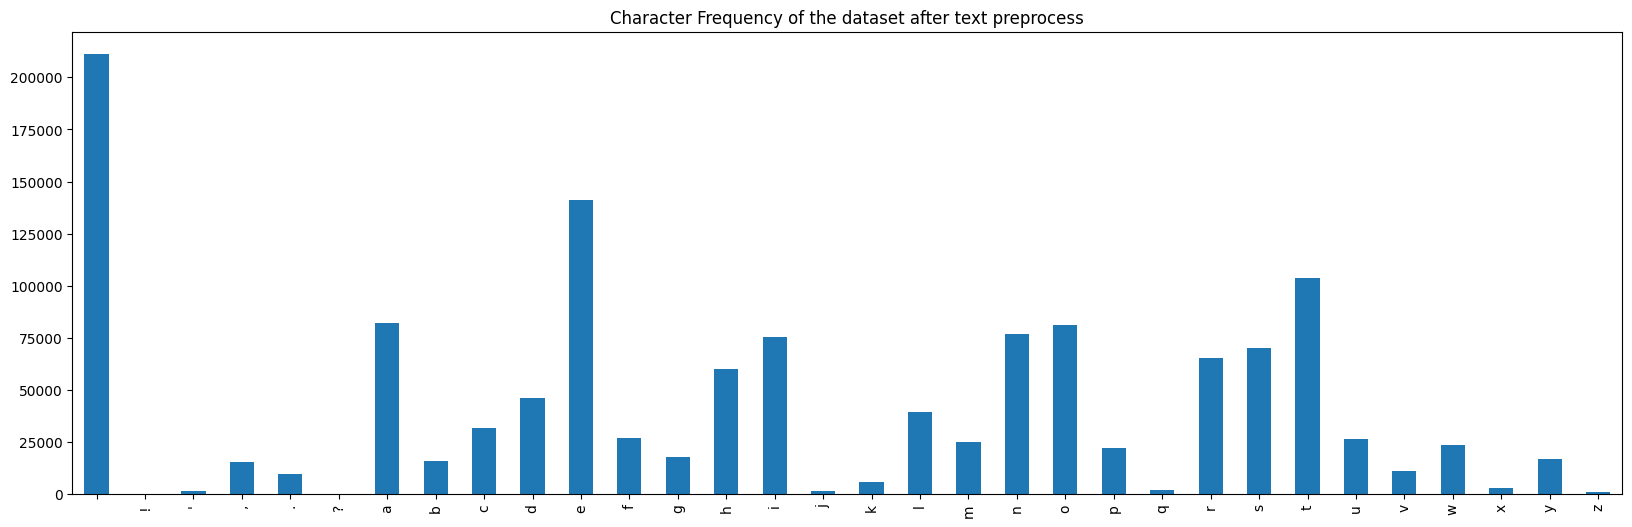

In [6]:
counts = pd.Series(list("".join(data["text"].dropna()))).value_counts()
symbols = sorted(c for c in counts.index if not c.isalnum())
letters = sorted((c for c in counts.index if c.isalpha()))
other = sorted(c for c in counts.index if c not in symbols + letters)

counts = counts.reindex(symbols + letters + other)
counts.plot.bar(figsize=(20, 6), title="Character Frequency of the dataset after text preprocess")
plt.show()

### Inspect sample mel spectrograms

These diagnostic plots show the time and frequency structure of example recordings. They support the audio checks rather than measuring generated speech quality.


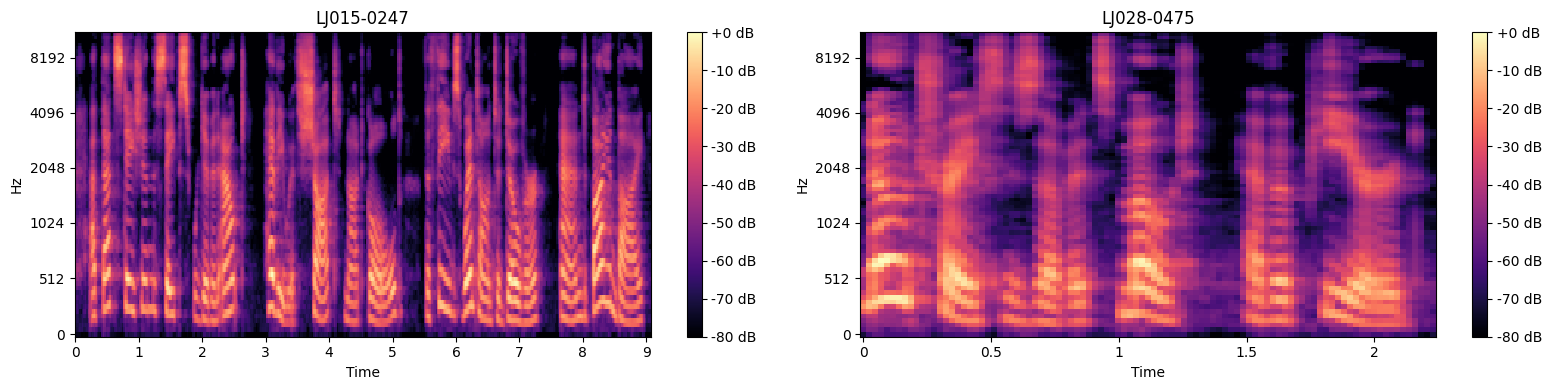

In [9]:
samples = data.sample(n=2)

plt.figure(figsize=(16, 4))
for i in range(2):
    row = samples.iloc[i]
    audio, _ = librosa.load(row["wav_path"], sr=SAMPLE_RATE, mono=True)  # representing the sound's changing amplitude,
    mel = librosa.feature.melspectrogram(y=audio, sr=SAMPLE_RATE,  n_mels=80)
    mel_db = librosa.power_to_db(mel, ref=mel.max())  # calcuate 10 * log10(S / ref)

    plt.subplot(1, 2, i + 1)
    image = librosa.display.specshow(mel_db, sr=SAMPLE_RATE, x_axis="time", y_axis="mel")
    plt.colorbar(image, format="%+d dB")
    plt.title(row["utt_id"])

plt.tight_layout()
plt.show()

### Create the fixed data selections

Build the seeded sampling pool, then draw the 800/100/100 selection used by Exp 0, Exp A and Exp B. Keep the sampling order unchanged so the saved test identities and speaker reference remain reproducible.


In [10]:
# Get Samples 2k
data = data.sample(n= MAX_SAMPLES_B, random_state=SEED).reset_index(drop=True)


train_data, remaining_data = train_test_split(data,test_size=0.20,random_state=SEED,shuffle=True)
val_data, test_data = train_test_split( remaining_data, test_size=0.50,random_state=SEED, shuffle=True)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)


train_data_1k = train_data.sample(n= int(MAX_SAMPLES_A *0.8) , random_state=SEED).reset_index(drop=True)
val_data_1k  = val_data.sample(n= int(MAX_SAMPLES_A * 0.1) , random_state=SEED).reset_index(drop=True)
test_data_1k = test_data.sample(n= int(MAX_SAMPLES_A * 0.1) , random_state=SEED).reset_index(drop=True)

print ("Experiment with 1000 samples")
print("Train:", len(train_data_1k))         # 80%
print("Validation:", len(val_data_1k))      # 10%
print("Test:", len(test_data_1k))           # 10%
print ("---------------------------------")



print ("\nExperiment with 2000 samples")
print("Train:", len(train_data))         # 80%
print("Validation:", len(val_data))      # 10%
print("Test:", len(test_data))           # 10%

Experiment with 1000 samples
Train: 800
Validation: 100
Test: 100
---------------------------------

Experiment with 2000 samples
Train: 1600
Validation: 200
Test: 200


## XTTS pipeline

### Model components

Prepared text passes through the XTTS-v2 BPE tokenizer and into its autoregressive GPT. The GPT predicts discrete DVAE audio codes, conditioned on a 32-vector voice prefix from a reference recording. The frozen HiFi-GAN decoder converts the predicted representation into a playable 24,000 Hz WAV, using the reference speaker embedding.

Exp 0 uses the original pretrained checkpoint. Exp A and Exp B fine-tune the GPT while keeping the DVAE, waveform decoder and speaker encoder frozen. The loss defined in this notebook is **0.5 times text-token cross-entropy plus 0.5 times audio-code cross-entropy**.

For training, each example takes its conditioning clip from a different recording of the same speaker. A slice between three and six seconds is used where the recording length permits. Inference reuses one fixed reference recording from the seeded training pool.

### Environment

The runs use Google Colab with an NVIDIA A100 GPU with 40 GB memory. The import cell records the runtime versions. The setup cell installs Coqui TTS, Whisper, JiWER, Unidecode and NeMo text processing, alongside the other imported dependencies.

### Run the three experiments

After running the setup and function-definition cells:

```python
run_experiment(experiments[0])  # Exp 0: pretrained model, no training
run_experiment(experiments[1])  # Exp A: 1,000 recordings, learning rate 1e-6
run_experiment(experiments[2])  # Exp B: 1,000 recordings, learning rate 1e-7
```

Each fine-tuning run saves its GPT checkpoint with the lowest validation loss and reloads it for testing. The frozen components come from the pretrained XTTS-v2 files.

### Generate a WAV from new text

```python
model = load_xtts(CHECKPOINT_DIR / "XTTS_expA" / "gpt_best.pth")
generate_examples(["Hello world."], model, run_name="XTTS_hello")
```

The WAV is saved as `wav_examples/XTTS_hello_01.wav`, and its measurements are written to the results directory. Calling `load_xtts()` without a GPT checkpoint loads the pretrained model for zero-shot generation.


## Experimental design

Every run starts from the same pretrained XTTS-v2 checkpoint and uses the same test selection, frozen decoder and inference reference. Seed 42 fixes the random state. The two adapted runs use the same effective batch size of eight and the same 20-epoch budget.

### Exp 0: zero-shot reference

- **Configuration:** The pretrained checkpoint generates speech without any weight updates.
- **Purpose:** Establish the reference level of word accuracy and generation speed before adaptation.
- **Evaluation:** The same 100 test sentences used by the adapted runs.

### Exp A: fine-tuning at 1e-6

- **Configuration:** Fine-tune the GPT on 800 training recordings, with 100 validation recordings and a learning rate of `1e-6`.
- **Purpose:** Test whether adaptation to the target voice improves the pretrained model's word accuracy.
- **Checkpoint:** Reload the GPT weights with the lowest validation loss.

### Exp B: fine-tuning at 1e-7

- **Controlled change:** Reduce the learning rate to `1e-7`, one tenth of Exp A's rate.
- **Fixed settings:** Use the same data selection, model components, batch size, epoch budget and evaluation procedure.
- **Purpose:** Test whether smaller updates give a better accuracy and speed trade-off under the same training budget.

### Generation and reproducibility

XTTS-v2 samples audio codes with temperature 0.75, top-k 50 and top-p 0.85. The generation seed is reset for each sentence. Training uses gradient accumulation so two microbatches of four examples form an effective update of eight examples.

The pretrained configuration is stored in `config.json`. Adapted GPT weights are saved in `checkpoints/XTTS_expA/gpt_best.pth` and `checkpoints/XTTS_expB/gpt_best.pth`. Per-sentence test metrics and prompt metrics are saved separately in `results/`. Training curves, printed summaries and audio previews remain in the notebook.


### Load XTTS-v2 and the fixed voice reference

Download the pretrained model files, prepare the frozen helper networks and extract the conditioning latents and speaker embedding from the fixed reference recording.


In [11]:
BASE_MODEL_FILES = ["config.json", "vocab.json", "model.pth", "dvae.pth", "mel_stats.pth", "speakers_xtts.pth"]
snapshot_download("coqui/XTTS-v2", local_dir=str(BASE_MODEL_DIR), allow_patterns=BASE_MODEL_FILES)

xtts_config = XttsConfig()
xtts_config.load_json(str(BASE_MODEL_DIR / "config.json"))

# Coqui's load_audio() uses torchaudio.load, which needs extra codecs on new torchaudio versions. Same result with librosa.
def load_audio(audiopath, sampling_rate):
    audio, _ = librosa.load(str(audiopath), sr=sampling_rate, mono=True)
    return torch.from_numpy(audio).unsqueeze(0).clip(-1, 1)

xtts_module.load_audio = load_audio

def load_xtts(gpt_weights=None, for_training=False):
    # for_training=False -> inference model (KV cache);  True -> GPT in training mode, all other parts frozen
    model = Xtts.init_from_config(xtts_config)
    model.load_checkpoint(xtts_config, checkpoint_dir=str(BASE_MODEL_DIR), eval=not for_training, use_deepspeed=False)
    if gpt_weights is not None:
        state = torch.load(gpt_weights, map_location="cpu")
        missing, unexpected = model.gpt.load_state_dict(state, strict=False)
        assert not unexpected, unexpected
        assert all(k.startswith(("gpt_inference.", "gpt.wte")) for k in missing), missing   # only inference aliases may be absent
    model = model.to(DEVICE)
    if for_training:
        torch.nn.Module.train(model, False)     # frozen parts in eval mode
        for parameter in model.parameters():
            parameter.requires_grad_(False)
        model.gpt.train()                       # the GPT is fully fine-tuned
        for parameter in model.gpt.parameters():
            parameter.requires_grad_(True)
    return model

# Frozen helpers, as in Coqui's GPTTrainer: mel extractors and the DVAE that turns audio into the target codes
mel_norm_file = str(BASE_MODEL_DIR / "mel_stats.pth")
conditioning_mel = TorchMelSpectrogram(filter_length=2048, hop_length=256, win_length=1024, normalize=False,
                                       sampling_rate=SAMPLE_RATE, mel_fmin=0, mel_fmax=8000, n_mel_channels=80,
                                       mel_norm_file=mel_norm_file).to(DEVICE)
dvae_mel = TorchMelSpectrogram(mel_norm_file=mel_norm_file, sampling_rate=xtts_config.audio.dvae_sample_rate).to(DEVICE)
dvae = DiscreteVAE(channels=80, normalization=None, positional_dims=1, num_tokens=xtts_config.model_args.gpt_num_audio_tokens - 2,
                   codebook_dim=512, hidden_dim=512, num_resnet_blocks=3, kernel_size=3, num_layers=2, use_transposed_convs=False)
dvae.load_state_dict(torch.load(BASE_MODEL_DIR / "dvae.pth", map_location="cpu"), strict=False)
dvae = dvae.to(DEVICE).eval()
for helper in (conditioning_mel, dvae_mel, dvae):
    for parameter in helper.parameters():
        parameter.requires_grad_(False)

model = load_xtts()
tokenizer = model.tokenizer

# Speaker reference: the first recording in the fixed training pool.
REFERENCE_WAV = train_data.iloc[0]["wav_path"]

def speaker_conditioning(model):
    # GPT conditioning latents (1, 32, 1024) and HiFi-GAN speaker embedding (1, 512, 1)
    with torch.no_grad():
        return model.get_conditioning_latents(audio_path=[str(REFERENCE_WAV)])

gpt_cond_latent, speaker_embedding = speaker_conditioning(model)
print("Reference utterance:", train_data.iloc[0]["utt_id"])
print("GPT conditioning latents:", tuple(gpt_cond_latent.shape), "| Speaker embedding:", tuple(speaker_embedding.shape))
print("Tokenizer vocabulary:", tokenizer.tokenizer.get_vocab_size())
del model
free_memory()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

/tmp/ipykernel_7416/3121821708.py:16: UserWarning: Xtts.init_from_config(config) is deprecated and will be removed soon, just initialize with Xtts(config)
  model = Xtts.init_from_config(xtts_config)
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 255), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 255), got 50256. This may result in unexpected behavior.
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 607), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 607), got 50256. This may result in unexpected behavior.


Reference utterance: LJ043-0158
GPT conditioning latents: (1, 32, 1024) | Speaker embedding: (1, 512, 1)
Tokenizer vocabulary: 6681


### Define the dataset and collator

Load each transcript and waveform, select a conditioning recording from the same speaker and pad the batch. The helper function creates conditioning mel features and target audio codes on the GPU.


In [12]:
MIN_COND_SAMPLES = getattr(xtts_config.model_args, "min_conditioning_length", 66150)     # 3 s
MAX_COND_SAMPLES = getattr(xtts_config.model_args, "max_conditioning_length", 132300)    # 6 s

def get_prompt_slice(wav, is_eval):
    # Adapted from TTS.tts.layers.xtts.trainer.dataset.get_prompt_slice
    if is_eval:
        length = (MIN_COND_SAMPLES + MAX_COND_SAMPLES) // 2          # fixed length and start for validation/test
    else:
        length = random.randint(MIN_COND_SAMPLES, MAX_COND_SAMPLES)
    if wav.shape[-1] - length < 0:
        length = wav.shape[-1] // 2
    start = 0 if is_eval else random.randint(0, wav.shape[-1] - length)
    clip = F.pad(wav[:, start:start + length], (0, MAX_COND_SAMPLES - length))
    return clip, length

class LJSpeechDataset(Dataset):

    def __init__(self, table, is_eval=False):
        self.table = table.reset_index(drop=True)
        self.is_eval = is_eval

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        audio, _ = librosa.load( row["wav_path"], sr=SAMPLE_RATE, mono=True)           # return Audio numpy "time_sec*sample_rate", and sample rate
        input_ids = torch.LongTensor(tokenizer.encode(row["text"], "en"))

        # Conditioning clip from another utterance of the same speaker (random for training, next sentence for val/test)
        partner = (index + 1) % len(self.table)
        if not self.is_eval:
            partner = random.randrange(len(self.table))
            if partner == index:
                partner = (partner + 1) % len(self.table)
        partner_audio, _ = librosa.load(self.table.iloc[partner]["wav_path"], sr=SAMPLE_RATE, mono=True)
        conditioning, cond_len = get_prompt_slice(torch.from_numpy(partner_audio).unsqueeze(0), self.is_eval)

        return {
            "input_ids": input_ids,
            "wav": torch.from_numpy(audio).unsqueeze(0),
            "conditioning": conditioning,
            "cond_len": torch.tensor(cond_len),
            "text": row["text"],
            "wav_path": row["wav_path"]}

class DataCollator:

    def __call__(self, features):
        text_lengths = torch.tensor([len(item["input_ids"]) for item in features])
        wav_lengths = torch.tensor([item["wav"].shape[-1] for item in features])

        #  Pad text and audio to the longest example in this batch.
        input_ids = torch.zeros(len(features), int(text_lengths.max()), dtype=torch.long)
        wav = torch.zeros(len(features), 1, int(wav_lengths.max()))
        for i, item in enumerate(features):
            input_ids[i, :text_lengths[i]] = item["input_ids"]
            wav[i, :, :wav_lengths[i]] = item["wav"]

        return {
            "input_ids": input_ids,
            "text_lengths": text_lengths,
            "wav": wav,
            "wav_lengths": wav_lengths,
            "conditioning": torch.stack([item["conditioning"] for item in features]),
            "cond_lens": torch.stack([item["cond_len"] for item in features]),
            # Keep original information for WER evaluation.
            "text": [item["text"] for item in features],
            "wav_path": [item["wav_path"] for item in features]}

@torch.no_grad()
def prepare_batch(batch):
    # Adapted from GPTTrainer.format_batch_on_device: conditioning mel and DVAE audio codes, computed on the GPU
    cond_mels = conditioning_mel(batch["conditioning"].to(DEVICE))                  # (B, 80, T)
    audio_codes = dvae.get_codebook_indices(dvae_mel(batch["wav"].to(DEVICE)))      # (B, T/4)
    return {"text_inputs": batch["input_ids"].to(DEVICE), "text_lengths": batch["text_lengths"].to(DEVICE),
            "audio_codes": audio_codes, "wav_lengths": batch["wav_lengths"].to(DEVICE),
            "cond_mels": cond_mels, "cond_lens": batch["cond_lens"].to(DEVICE)}

### Build the experiment DataLoaders

Create the training, validation and test loaders for the 800/100/100 selection. All three experiments use these loaders.


In [13]:
train_dataset_1k = LJSpeechDataset(train_data_1k)
val_dataset_1k = LJSpeechDataset(val_data_1k, is_eval=True)
test_dataset_1k = LJSpeechDataset(test_data_1k, is_eval=True)
#######



data_collator = DataCollator()

generator = torch.Generator().manual_seed(SEED)

train_loader_1k = DataLoader(
    train_dataset_1k,
    batch_size=MICRO_BATCH,
    shuffle=True,
    generator=generator,
    collate_fn=data_collator,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader_1k = DataLoader(
    val_dataset_1k,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader_1k = DataLoader(
    test_dataset_1k,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

loaders_1k = { "train": train_loader_1k, "val": val_loader_1k,"test": test_loader_1k }

print("Train batches:", len(loaders_1k["train"]))
print("Validation batches:", len(loaders_1k["val"]))
print("Test batches:", len(loaders_1k["test"]))

Train batches: 200
Validation batches: 13
Test batches: 13


### Inspect a batch

Check the tensor shapes and sequence lengths before training or inference.


In [14]:
batch = next(iter(loaders_1k["train"]))
processed = prepare_batch(batch)
print("Text tokens:", batch["input_ids"].shape)
print("Waveforms (22.05 kHz):", batch["wav"].shape)
print("Audio codes (DVAE targets):", processed["audio_codes"].shape)
print("Conditioning mels:", processed["cond_mels"].shape)

Text tokens: torch.Size([4, 74])
Waveforms (22.05 kHz): torch.Size([4, 1, 189341])
Audio codes (DVAE targets): torch.Size([4, 185])
Conditioning mels: torch.Size([4, 80, 517])


### Inspect the sampling-pool DataLoaders

These loaders retain the intermediate pool statistics used during data preparation. The submitted experiment configurations below all select `loaders_1k`.


In [15]:
train_dataset = LJSpeechDataset(train_data)
val_dataset = LJSpeechDataset(val_data, is_eval=True)
test_dataset = LJSpeechDataset(test_data, is_eval=True)

train_loader = DataLoader(
    train_dataset,
    batch_size=MICRO_BATCH,
    shuffle=True,
    generator=generator,
    collate_fn=data_collator,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

loader_f = { "train": train_loader, "val": val_loader,"test": test_loader }

print("Train batches:", len(loader_f["train"]))
print("Validation batches:", len(loader_f["val"]))
print("Test batches:", len(loader_f["test"]))

Train batches: 400
Validation batches: 25
Test batches: 25


### Define the loss and validation calculation

Combine text-token and audio-code cross-entropy with equal weights of 0.5. Validation averages this loss over its batches without gradient updates. Exp 0 performs inference directly from the pretrained weights.


In [16]:
TEXT_CE_WEIGHT, MEL_CE_WEIGHT = 0.5, 0.5     # Equal weights for text-token and audio-code cross-entropy.

def compute_loss(model, batch):
    inputs = prepare_batch(batch)
    loss_text, loss_mel, _ = model.gpt(
        inputs["text_inputs"], inputs["text_lengths"], inputs["audio_codes"], inputs["wav_lengths"],
        cond_mels=inputs["cond_mels"],
        cond_idxs=None,                                  # no masking: the conditioning clip comes from another utterance
        cond_lens=inputs["cond_lens"].clone(),           # forward() rescales cond_lens in place
    )
    return TEXT_CE_WEIGHT * loss_text + MEL_CE_WEIGHT * loss_mel

def evaluation(model, val_loader):

    epoch_val_loss = []
    model.gpt.eval()
    with torch.no_grad():
        for batch in val_loader:
            epoch_val_loss.append(compute_loss(model, batch).item())

    return sum(epoch_val_loss) / len(epoch_val_loss)

### Define training and checkpoint saving

Train only the GPT with AdamW and gradient accumulation. Save `gpt_best.pth` whenever validation loss improves.


In [17]:
def train(model, data_loader, lr=LEARNING_RATE_A, epoch_num=EPOCHS, check_point= None):

    optimizer = torch.optim.AdamW([p for p in model.gpt.parameters() if p.requires_grad], lr=lr)
    train_loss = []
    val_loss = []
    best_val_loss = float("inf")
    n_batches = len(data_loader["train"])

    print(f"{'Epoch':<10}{'Batch':<12}{'Train Loss':>18}{'Validation Loss':>18}")
    print("-" * 58)

    for epoch in range(epoch_num):

        model.gpt.train()
        epoch_train_loss = []
        optimizer.zero_grad()
        for bn, batch in enumerate(data_loader["train"], start=1):
            loss = compute_loss(model, batch)
            if torch.isfinite(loss):
                (loss / GRAD_ACCUM).backward()          # GRAD_ACCUM micro-batches = one update of BATCH_SIZE samples
                epoch_train_loss.append(loss.item())
            if bn % GRAD_ACCUM == 0 or bn == n_batches:
                optimizer.step()
                optimizer.zero_grad()
            average_train_loss = sum(epoch_train_loss) / max(len(epoch_train_loss), 1)
            print(f"\r{f'{epoch + 1}/{epoch_num}':<10}{f'{bn}/{n_batches}':<12}{average_train_loss:>18.4f}{'-':>18}", end="")


        average_train_loss = (sum(epoch_train_loss)/ max(len(epoch_train_loss), 1))

        average_val_loss = evaluation( model, data_loader["val"] )

        train_loss.append(average_train_loss)
        val_loss.append(average_val_loss)

        print(f"\r{f'{epoch + 1}/{epoch_num}':<10}{f'{bn}/{n_batches}':<12}{average_train_loss:>18.4f}{average_val_loss:>18.4f}", end="")
        print()


        if average_val_loss < best_val_loss:
            best_val_loss = average_val_loss
            torch.save(model.gpt.state_dict(), Path(check_point) / "gpt_best.pth")     # GPT weights only, the rest is frozen

    print("Training completed")
    print(f"Best validation loss: {best_val_loss:.4f}")

    return {"Training Loss": train_loss, "Validation Loss": val_loss}

### Define test-set evaluation

Generate each test sentence once, measure complete-waveform latency and RTF, and use Whisper `base.en` with JiWER to calculate WER. Save the per-sentence measurements and their means to a CSV file.


In [18]:
asr_model = whisper.load_model("base.en", device=DEVICE)

# XTTS-v2 default sampling settings, fixed explicitly
GENERATION_KWARGS = dict(temperature=0.75, length_penalty=1.0, repetition_penalty=10.0, top_k=50, top_p=0.85, do_sample=True, speed=1.0)

def synthesize(model, text, conditioning, seed):
    # text -> 24 kHz waveform. The seed makes the sampled output reproducible.
    gpt_cond_latent, speaker_embedding = conditioning
    torch.manual_seed(seed)
    with torch.no_grad():
        out = model.inference(text, "en", gpt_cond_latent, speaker_embedding, enable_text_splitting=False, **GENERATION_KWARGS)
    return np.asarray(out["wav"], dtype=np.float32).reshape(-1)

def transcribe(audio_24k):
    # Whisper expects a 16 kHz waveform
    audio_16k = torchaudio.functional.resample(torch.from_numpy(audio_24k), OUTPUT_SAMPLE_RATE, ASR_SAMPLE_RATE).numpy()
    return asr_model.transcribe(audio_16k.astype(np.float32), language="en", fp16=(DEVICE == "cuda"), verbose=None)["text"]

def evaluation_metrics(model, test_loader, run_name):

    model.eval()
    conditioning = speaker_conditioning(model)

    rows = []
    sample_number = 0
    for batch in test_loader:
        for i in range(len(batch["text"])):
            sample_number += 1
            print(f"\r Sample {sample_number}/{len(test_loader.dataset)}     ", end="")
            ref_text = batch["text"][i]

            # Measure generation time.
            sync()
            start = time.time()

            generated_audio = synthesize(model, ref_text, conditioning, seed=SEED + sample_number)

            sync()
            latency  = time.time() - start       # latency_values

            audio_seconds  = len(generated_audio) / OUTPUT_SAMPLE_RATE
            rtf = latency / audio_seconds

            # WER
            normalise = jiwer.Compose([jiwer.RemovePunctuation(), jiwer.RemoveMultipleSpaces(), jiwer.Strip()])
            predicted_text = transcribe(generated_audio)
            wer_percent = 100 * jiwer.wer(normalise(clean_text(ref_text, num_handle = 1)),normalise(clean_text(predicted_text, num_handle = 1)))

            rows.append({
                "sample": sample_number,
                "reference_text": ref_text,
                "predicted_text": predicted_text,
                "latency_seconds": latency,
                "audio_seconds": audio_seconds,
                "rtf": rtf,
                "wer_percent": wer_percent,
            })

    print()
    df = pd.DataFrame(rows)
    means = df[["latency_seconds", "audio_seconds", "rtf", "wer_percent"]].mean()
    df.loc[len(df)] = {
    "sample": "MEAN",
    "latency_seconds": df["latency_seconds"].mean(),
    "audio_seconds": df["audio_seconds"].mean(),
    "rtf": df["rtf"].mean(),
    "wer_percent": df["wer_percent"].mean(),
    }

    output_path = RESULTS_DIR / f"{run_name}_metrics_Testset.csv"
    df.to_csv(output_path, index=False)
    print(f"\nSaved: {output_path}")


    return means["latency_seconds"], means["rtf"], means["wer_percent"]

100%|████████████████████████████████████████| 139M/139M [00:00<00:00, 346MiB/s]


### Define prompt generation

Generate a WAV for each prompt, record latency, audio duration, RTF and WER, and display the first file as an audio preview. A separate warm-up call runs before prompt timing.


In [19]:
def generate_examples(Prompts_list, model, run_name ="A"):

    PROMPTS_C = [clean_text(p, num_handle = 1) for p in Prompts_list]   # Clean the prompts and expand numbers before synthesis.

    results = []
    model.eval()
    conditioning = speaker_conditioning(model)

    normalise = jiwer.Compose([jiwer.RemovePunctuation(), jiwer.RemoveMultipleSpaces(), jiwer.Strip()])

    # Warm-up: run once without timing, so the first prompt is not slower than the rest.
    synthesize(model, PROMPTS_C[0], conditioning, seed=SEED)
    sync()


    for index, text in enumerate(PROMPTS_C, start=1):

        sync()
        start = time.time()

        audio = synthesize(model, text, conditioning, seed=SEED + index)

        sync()
        generation_time = time.time() - start

        output_path = OUTPUT_DIR / f"{run_name}_{index:02d}.wav"
        sf.write(str(output_path), audio, OUTPUT_SAMPLE_RATE)

        audio_seconds  = len(audio) / OUTPUT_SAMPLE_RATE
        rtf = generation_time / audio_seconds

        asr_text = transcribe(audio)

        wer_percent = 100 * jiwer.wer(normalise(clean_text(text, num_handle = 1)),normalise(clean_text(asr_text, num_handle = 1)))

        results.append({
            "file": output_path.name,
            "prompt ": Prompts_list[index - 1],
            "asr_text": asr_text,
            "generation_seconds": generation_time,
            "audio_seconds": audio_seconds,
            "rtf": rtf,
            "wer_percent": wer_percent
        })



    metrics = pd.DataFrame(results)
    metrics.loc[len(metrics)] = {
        "file": "MEAN",
        "generation_seconds": metrics["generation_seconds"].mean(),
        "audio_seconds": metrics["audio_seconds"].mean(),
        "rtf": metrics["rtf"].mean(),
        "wer_percent": metrics["wer_percent"].mean()
    }


    csv_path = RESULTS_DIR / f"{run_name}_metrics_generation.csv"
    metrics.to_csv(csv_path, index=False)
    print(f"\nSaved: {csv_path}")

    print (f"{run_name} Result")
    print(metrics[["file", "generation_seconds", "audio_seconds", "rtf", "wer_percent"]].to_string(index=False))


    first_file = OUTPUT_DIR / f"{run_name}_01.wav"
    display(Audio(filename=str(first_file)))

### Define the complete experiment workflow

Reset the random state, train when required, restore the selected checkpoint, evaluate the test split and generate the 12 prompt WAVs. Exp 0 skips training and uses the original pretrained checkpoint.


In [20]:
def run_experiment(experiments_index):

  run_name, loaders, learning_rate = experiments_index

  print(f"\n -----------Starting {run_name} -----------")
  run_checkpoint_dir = CHECKPOINT_DIR / run_name
  run_checkpoint_dir.mkdir(parents=True, exist_ok=True)
  random.seed(SEED)
  np.random.seed(SEED)
  torch.manual_seed(SEED)
  generator.manual_seed(SEED)  # reset the generator used by the training DataLoaders

  best_weights = None
  if run_name != f"{RUN_PREFIX}exp0":     # exp 0 it will generate audio without training
      model = load_xtts(for_training=True)

      # 1. Train the model.
      history = train(model,loaders ,lr=learning_rate, epoch_num= EPOCHS, check_point=run_checkpoint_dir)

      # 2. Plot training and validation loss.
      train_losses = history["Training Loss"]
      val_losses = history["Validation Loss"]
      epochs = range(1, len(train_losses) + 1)

      best_val = min(val_losses)
      best_epoch = val_losses.index(best_val) + 1

      plt.figure(figsize=(8, 4))
      plt.plot(epochs, train_losses, "o-", label="Training loss")
      plt.plot(epochs, val_losses, "o-", label="Validation loss")
      plt.plot(best_epoch, best_val, "*", markersize=10, label=f"Best val loss ({best_val:.4f} @ epoch {best_epoch})")
      plt.xlabel("Epoch")
      plt.ylabel("Loss")
      plt.title(run_name)
      plt.legend()
      plt.show()

      # Free the training model before loading its best checkpoint.
      del model
      free_memory()

      # load best model parameters from check point
      best_weights = run_checkpoint_dir / "gpt_best.pth"
      model = load_xtts(best_weights, for_training=True)
      # 3. Test loss.
      test_loss = evaluation(model, loaders["test"])
      print(f"{run_name}, Testing loss: {test_loss:.4f}")
      del model
      free_memory()

  model = load_xtts(best_weights)     # inference model (pretrained for exp0, best checkpoint otherwise)

  # 4. Generation metrics.
  print('\n ---- evaluation metrics ----')
  mean_lat, mean_rtf, mean_wer = evaluation_metrics(model, loaders["test"], run_name)
  print(f"Mean latency: {mean_lat:.4f}")
  print(f"Mean RTF: {mean_rtf:.4f}")
  print(f"Mean WER: {mean_wer:.2f}%")


  generate_examples(PROMPTS, model, run_name)  # Save this run's 12 WAV files.

  del model
  free_memory()
  print("-" * 70)

### Fixed qualitative prompts

Use these 12 sentences for every experiment. They cover ordinary narration, punctuation, numbers, place names and spoken titles.


In [21]:
PROMPTS = [
    "The quick brown fox jumps over the lazy dog.",
    "Adelaide has great weather in spring.",
    "Thank you for listening to this file.",
    "Our group did excellent work on assignment 3.",
    "Can you hear the difference between these 2 voices?",
    "What a great result for our first experiment!",
    "We need clean text, and enough training time.",
    "The first model was fast, the second model sounded more natural.",
    "I don't believe it is ready, but we will try it again tomorrow.",
    "At the university, Dr. Brown and Mrs. Lee met Mr. Clark.",
    "The class begins at nine and there are forty-five students in the class.",
    "The model should be able to read new sentences clearly, and maintain a consistent reading speed; and pause at the correct location."
]

### Configure Exp 0, Exp A and Exp B

Only these three runs are included in the submission. Each uses the same 1,000-recording selection and its 100-sentence test split.


In [22]:
experiments = [
    (f"{RUN_PREFIX}exp0", loaders_1k, 0),                    # Fixed 1,000-recording selection, no training.
    (f"{RUN_PREFIX}expA", loaders_1k, LEARNING_RATE_A),      # Fixed 1,000-recording selection, learning rate 1e-6.
    (f"{RUN_PREFIX}expB", loaders_1k, LEARNING_RATE_B),      # Fixed 1,000-recording selection, learning rate 1e-7.
]


### Run Exp 0

Evaluate the pretrained model without training and save its test metrics and prompt WAVs.


In [25]:
run_experiment(experiments[0])


 -----------Starting XTTS_exp0 -----------


/tmp/ipykernel_7416/3121821708.py:16: UserWarning: Xtts.init_from_config(config) is deprecated and will be removed soon, just initialize with Xtts(config)
  model = Xtts.init_from_config(xtts_config)



 ---- evaluation metrics ----
 Sample 100/100     

Saved: /content/drive/MyDrive/Zaid/results/XTTS_exp0_metrics_Testset.csv
Mean latency: 3.5835
Mean RTF: 0.4546
Mean WER: 10.12%

Saved: /content/drive/MyDrive/Zaid/results/XTTS_exp0_metrics_generation.csv
XTTS_exp0 Result
            file  generation_seconds  audio_seconds      rtf  wer_percent
XTTS_exp0_01.wav            3.001116       6.634667 0.452339    66.666667
XTTS_exp0_02.wav            2.344593       5.152000 0.455084    33.333333
XTTS_exp0_03.wav            1.177181       2.506667 0.469620     0.000000
XTTS_exp0_04.wav            1.971184       4.362667 0.451830    12.500000
XTTS_exp0_05.wav            1.560011       3.381333 0.461360     0.000000
XTTS_exp0_06.wav            1.502388       3.242667 0.463319     0.000000
XTTS_exp0_07.wav            1.744014       3.808000 0.457987     0.000000
XTTS_exp0_08.wav            1.842883       4.032000 0.457064     0.000000
XTTS_exp0_09.wav            1.743184       3.808000 0.45776

----------------------------------------------------------------------


### Run Exp A

Fine-tune the GPT with a learning rate of `1e-6`, then evaluate the selected checkpoint and generate the prompt WAVs.



 -----------Starting XTTS_expA -----------


/tmp/ipykernel_7416/3121821708.py:16: UserWarning: Xtts.init_from_config(config) is deprecated and will be removed soon, just initialize with Xtts(config)
  model = Xtts.init_from_config(xtts_config)


Epoch     Batch               Train Loss   Validation Loss
----------------------------------------------------------
1/20      200/200                 2.8980            2.7953
2/20      200/200                 2.7721            2.7335
3/20      200/200                 2.7155            2.6977
4/20      200/200                 2.6772            2.6731
5/20      200/200                 2.6456            2.6559
6/20      200/200                 2.6214            2.6421
7/20      200/200                 2.6005            2.6316
8/20      200/200                 2.5846            2.6224
9/20      200/200                 2.5651            2.6143
10/20     200/200                 2.5517            2.6072
11/20     200/200                 2.5381            2.6011
12/20     200/200                 2.5266            2.5956
13/20     200/200                 2.5114            2.5919
14/20     200/200                 2.4996            2.5876
15/20     200/200                 2.4921            2.58

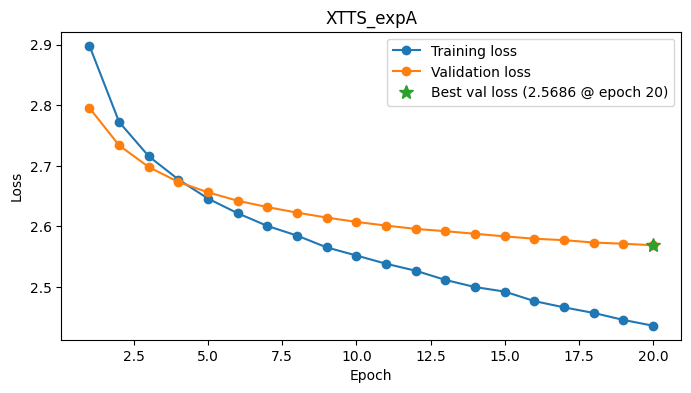

XTTS_expA, Testing loss: 2.5436

 ---- evaluation metrics ----
 Sample 100/100     

Saved: /content/drive/MyDrive/Zaid/results/XTTS_expA_metrics_Testset.csv
Mean latency: 2.9201
Mean RTF: 0.4608
Mean WER: 3.59%

Saved: /content/drive/MyDrive/Zaid/results/XTTS_expA_metrics_generation.csv
XTTS_expA Result
            file  generation_seconds  audio_seconds      rtf  wer_percent
XTTS_expA_01.wav            1.468910       3.200000 0.459034          0.0
XTTS_expA_02.wav            1.244248       2.506667 0.496375          0.0
XTTS_expA_03.wav            0.980474       1.994667 0.491548          0.0
XTTS_expA_04.wav            1.843627       3.946667 0.467135          0.0
XTTS_expA_05.wav            1.467525       3.200000 0.458602          0.0
XTTS_expA_06.wav            1.467645       3.200000 0.458639          0.0
XTTS_expA_07.wav            1.442620       3.008000 0.479594          0.0
XTTS_expA_08.wav            1.992474       4.405333 0.452287          0.0
XTTS_expA_09.wav            

----------------------------------------------------------------------


In [23]:
run_experiment(experiments[1])

### Run Exp B

Repeat the same workflow with a learning rate of `1e-7`.



 -----------Starting XTTS_expB -----------


/tmp/ipykernel_7416/3121821708.py:16: UserWarning: Xtts.init_from_config(config) is deprecated and will be removed soon, just initialize with Xtts(config)
  model = Xtts.init_from_config(xtts_config)


Epoch     Batch               Train Loss   Validation Loss
----------------------------------------------------------
1/20      200/200                 3.0484            2.9977
2/20      200/200                 2.9901            2.9440
3/20      200/200                 2.9460            2.9076
4/20      200/200                 2.9145            2.8814
5/20      200/200                 2.8884            2.8611
6/20      200/200                 2.8691            2.8446
7/20      200/200                 2.8521            2.8307
8/20      200/200                 2.8397            2.8187
9/20      200/200                 2.8230            2.8080
10/20     200/200                 2.8155            2.7984
11/20     200/200                 2.8038            2.7896
12/20     200/200                 2.7951            2.7816
13/20     200/200                 2.7852            2.7743
14/20     200/200                 2.7782            2.7675
15/20     200/200                 2.7732            2.76

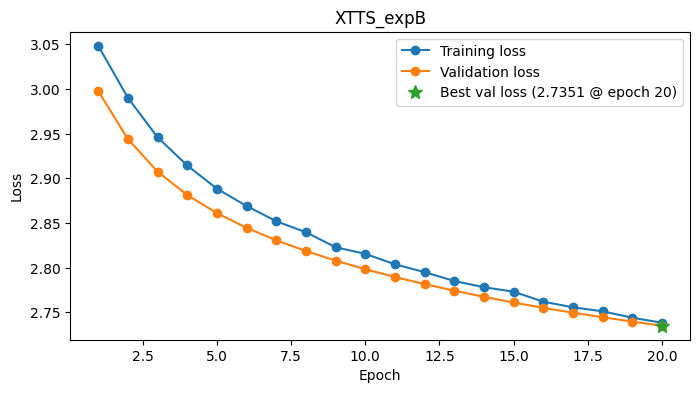

XTTS_expB, Testing loss: 2.7041

 ---- evaluation metrics ----
 Sample 100/100     

Saved: /content/drive/MyDrive/Zaid/results/XTTS_expB_metrics_Testset.csv
Mean latency: 3.1378
Mean RTF: 0.4588
Mean WER: 5.30%

Saved: /content/drive/MyDrive/Zaid/results/XTTS_expB_metrics_generation.csv
XTTS_expB Result
            file  generation_seconds  audio_seconds      rtf  wer_percent
XTTS_expB_01.wav            1.583742       3.338667 0.474364     0.000000
XTTS_expB_02.wav            1.583757       3.296000 0.480509     0.000000
XTTS_expB_03.wav            1.084961       2.176000 0.498603     0.000000
XTTS_expB_04.wav            1.849992       4.085333 0.452837     0.000000
XTTS_expB_05.wav            1.540484       3.242667 0.475067     0.000000
XTTS_expB_06.wav            1.563557       3.381333 0.462408     0.000000
XTTS_expB_07.wav            1.554710       3.381333 0.459792     0.000000
XTTS_expB_08.wav            2.102238       4.640000 0.453068     0.000000
XTTS_expB_09.wav            

----------------------------------------------------------------------


In [24]:
run_experiment(experiments[2])

In [ ]:
from google.colab import runtime
runtime.unassign()

## Evaluation and saved artefacts

### Objective metrics

- **Latency:** Time in seconds to generate a complete test waveform, including the GPT and HiFi-GAN decoder. GPU synchronisation brackets the timed generation call.
- **Real-time factor:** Generation time divided by generated audio duration. Values below one mean generation is faster than playback.
- **Word error rate:** Whisper `base.en` transcribes the audio after resampling to 16 kHz. Text cleaning and JiWER normalisation prepare the reference and transcript for comparison. Lower WER means fewer word edits.

Each experiment generates the same 100 test sentences once. The test CSV records every sentence and a final mean row. The comparison in the final section uses the printed test-set means, rather than the separate prompt summaries.

### Qualitative evidence

The 12 fixed prompts generate 36 WAV files across the three runs, named `XTTS_exp0_01.wav` to `XTTS_exp0_12.wav`, `XTTS_expA_01.wav` to `XTTS_expA_12.wav`, and `XTTS_expB_01.wav` to `XTTS_expB_12.wav`. Each run also saves prompt-level metrics and displays an audio preview.

### Running the submission

Place `LJSpeech-1.1.tar.bz2` in the configured project folder or `/content`, select an A100 runtime and run the setup and function-definition cells. Run the three calls listed in the pipeline section. Checkpoints are saved in `checkpoints/`, generated audio in `wav_examples/` and metrics in `results/`.

### Sources

- **Dataset:** [LJSpeech 1.1](https://keithito.com/LJ-Speech-Dataset/).
- **Model and design:** [XTTS-v2 model card](https://huggingface.co/coqui/XTTS-v2) and [Coqui XTTS documentation](https://docs.coqui.ai/en/latest/models/xtts.html).
- **Training implementation:** Coqui `GPTTrainer` and dataset routines informed the DVAE targets and conditioning slices. The loss weights used here are defined explicitly in the loss cell. See the [Coqui TTS codebase](https://github.com/idiap/coqui-ai-TTS).
- **Evaluation:** [OpenAI Whisper](https://github.com/openai/whisper) and [JiWER](https://github.com/jitsi/jiwer).
- **Supporting libraries:** PyTorch, Transformers, librosa, SoundFile, pandas, Unidecode and NeMo text processing.


## Results and project scope

The table below reproduces the saved test-set summaries. Every run uses the same 100 test sentences, with one generation per sentence. Lower values are better for latency, RTF and WER.

| Experiment | Model setup | Learning rate | Test sentences | Mean latency (s) | Mean RTF | Mean WER (%) |
| --- | --- | --- | ---: | ---: | ---: | ---: |
| Exp 0 | Pretrained, zero-shot inference | No training | 100 | 3.5835 | 0.4546 | 10.12 |
| Exp A | GPT fine-tuning, 20 epochs | 1e-6 | 100 | 2.9201 | 0.4608 | 3.59 |
| Exp B | GPT fine-tuning, 20 epochs | 1e-7 | 100 | 3.1378 | 0.4588 | 5.30 |

Exp A has the lowest XTTS word error rate and shortest mean completion time. Its WER is 6.53 percentage points lower than Exp 0. Exp B also improves word accuracy, but less than Exp A under the same epoch budget. RTF remains close to 0.46 across all three runs, so fine-tuning improves word accuracy without a corresponding improvement in generation time per second of audio. Exp 0 has the lowest mean RTF despite its higher completion latency because its generated recordings have different durations.

### Why XTTS was not included in the main report

- **Fewer experiments:** We completed a zero-shot reference and two fine-tuning conditions. This is a narrower experimental study than the two models retained in the main report.
- **Overall performance:** XTTS did not offer a better overall accuracy and generation-speed trade-off than the selected systems. Exp A was the strongest XTTS run, but it did not improve on the strongest retained system and its RTF was higher than either selected pipeline. The decision reflects the combined trade-off rather than a claim that XTTS was worse on every metric.
- **Model design and project focus:** XTTS-v2 is designed for reference-conditioned voice cloning, including zero-shot use with a short speaker recording. This made it useful as an additional zero-shot comparison, while the main report focused on a broader set of controlled adaptation experiments. XTTS supports GPT fine-tuning, and the improvements above show that adaptation can still help.

The [official model card](https://huggingface.co/coqui/XTTS-v2) and [XTTS documentation](https://docs.coqui.ai/en/latest/models/xtts.html) describe its reference-based voice cloning and fine-tuning support. The overall performance comparison follows the selected pipelines in the companion project report.
